In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan))
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [6]:
df = df.dropna().reset_index(drop=True)
df['Avg_Total_Per_Month'] = df['TotalCharges'] / (df['tenure'] + 1)
df.shape

(7032, 22)

In [7]:
df['Churn'].value_counts(normalize=True)

Churn
No     0.734215
Yes    0.265785
Name: proportion, dtype: float64

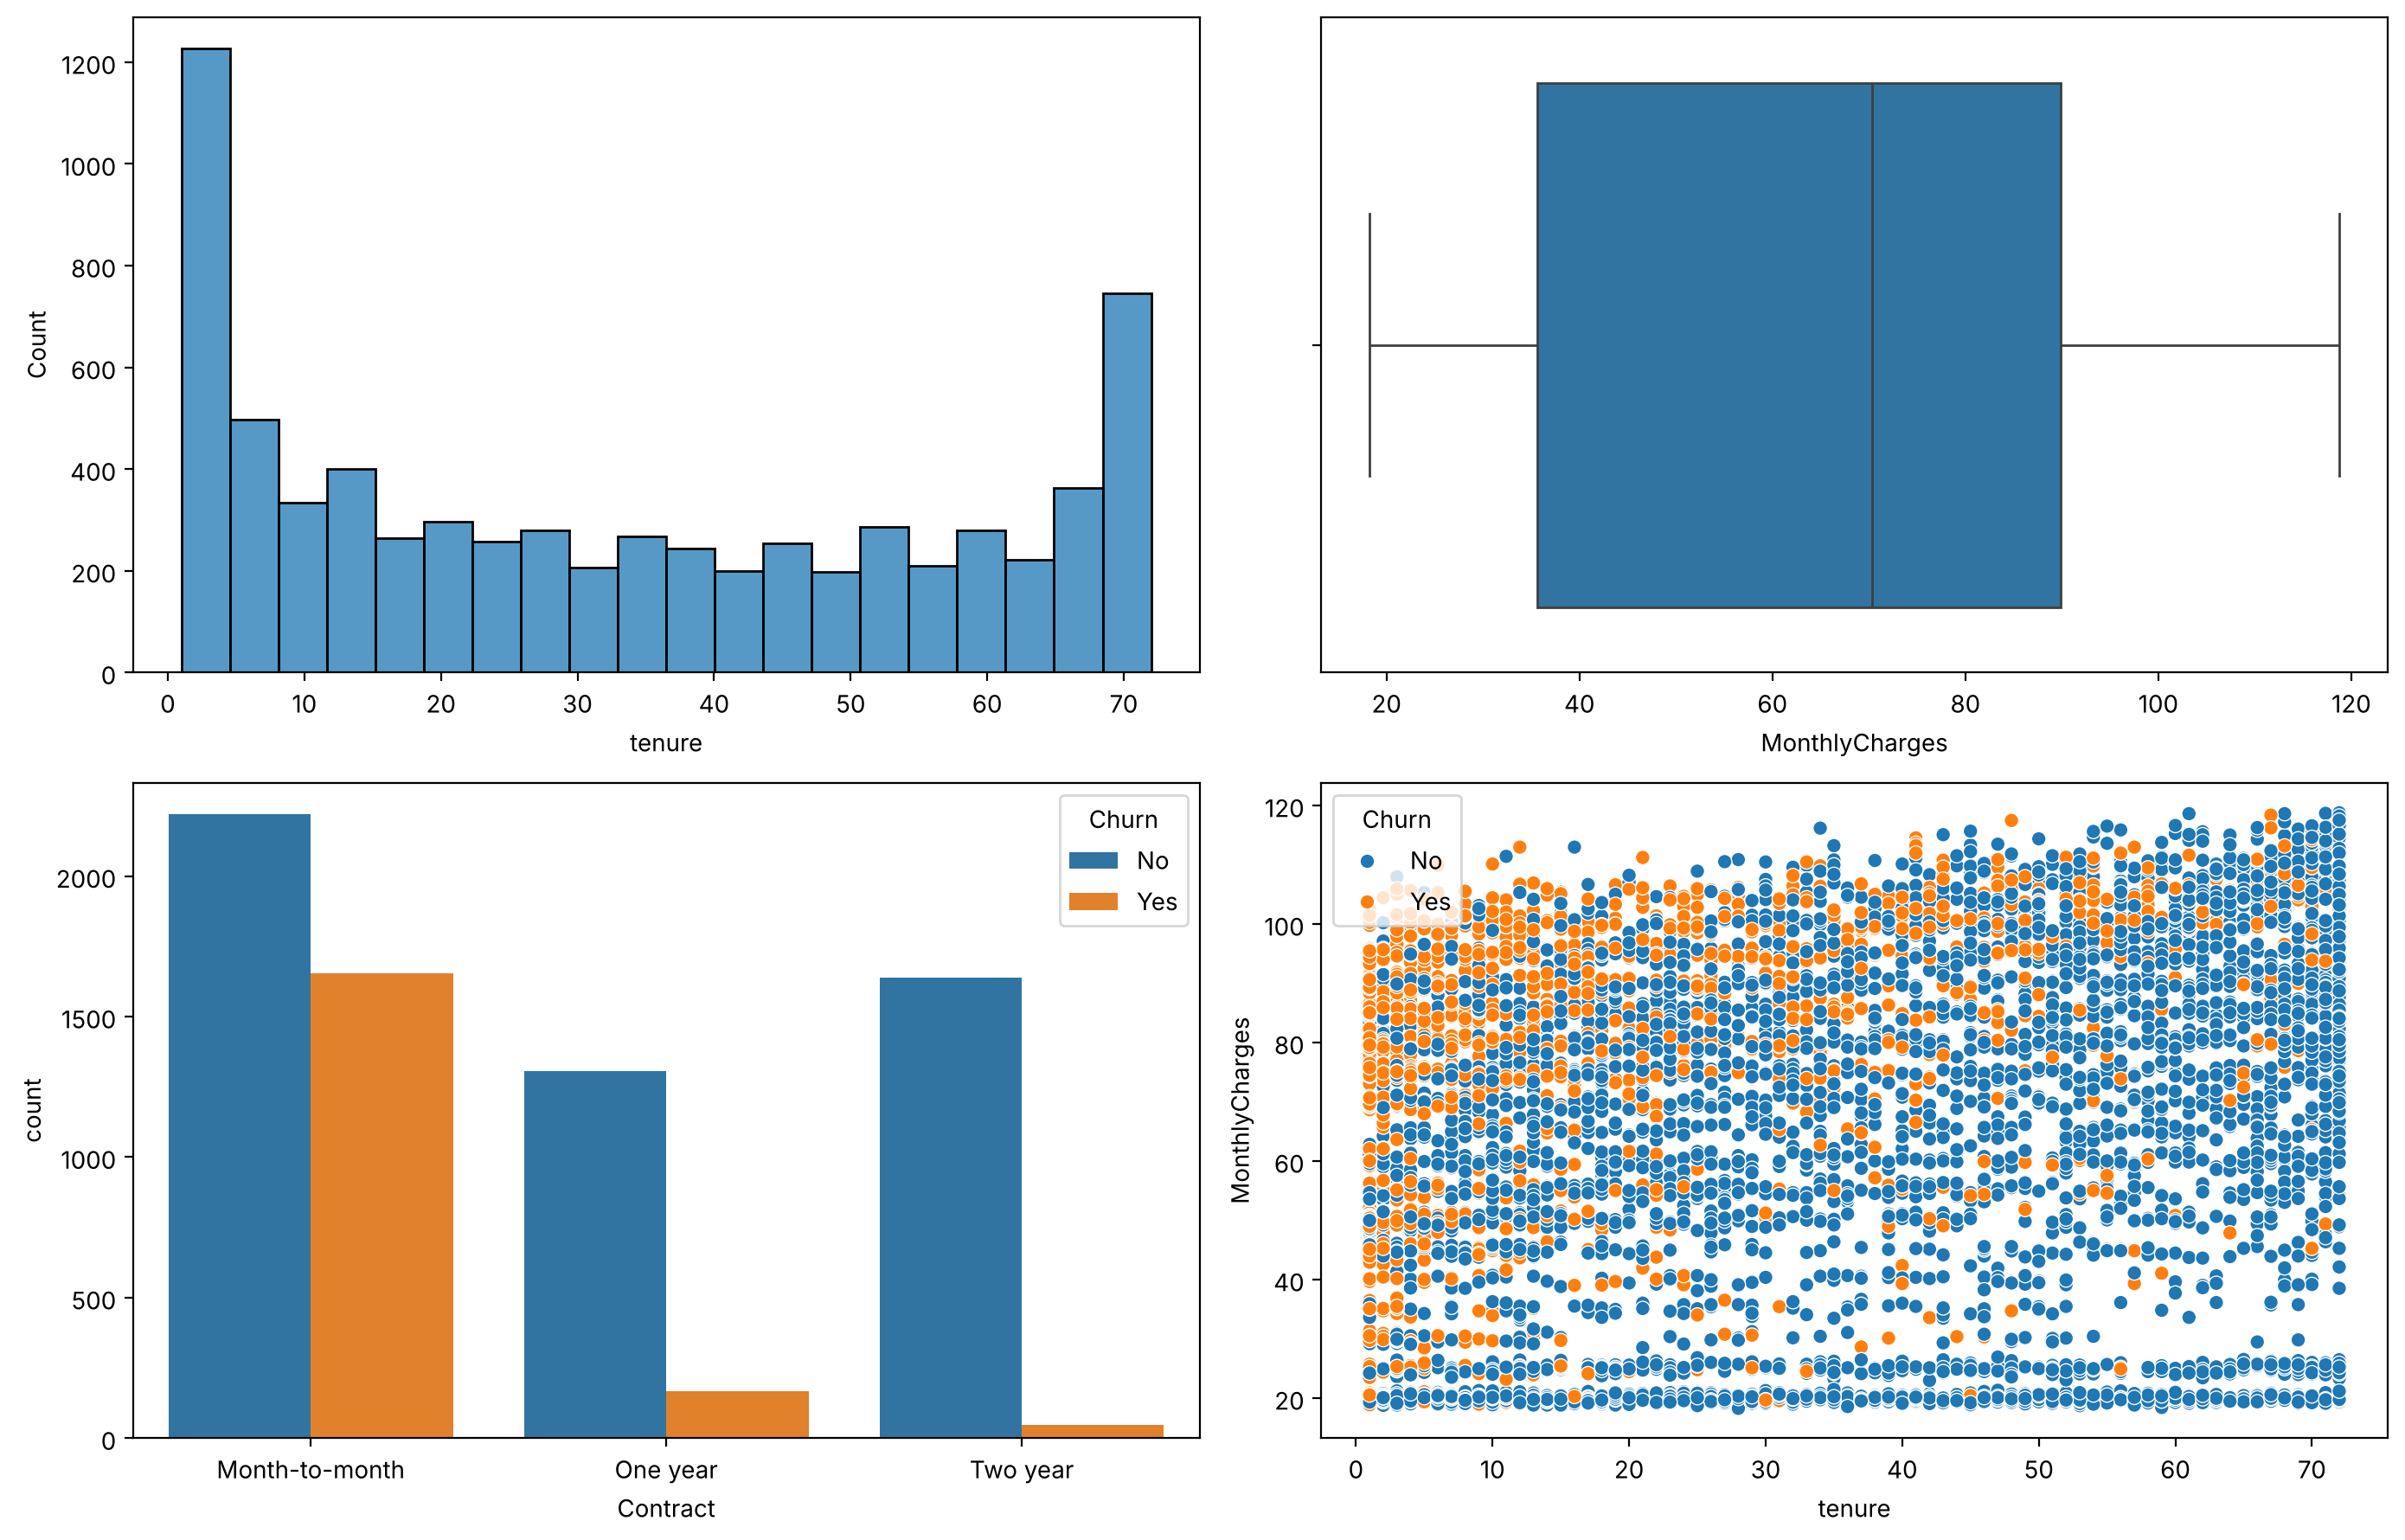

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(data=df, x='tenure', bins=20, ax=axes[0, 0])
sns.boxplot(data=df, x='MonthlyCharges', ax=axes[0, 1])
sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[1, 0])
sns.scatterplot(data=df, x='tenure', y='MonthlyCharges', hue='Churn', ax=axes[1, 1])
plt.tight_layout()
plt.show()

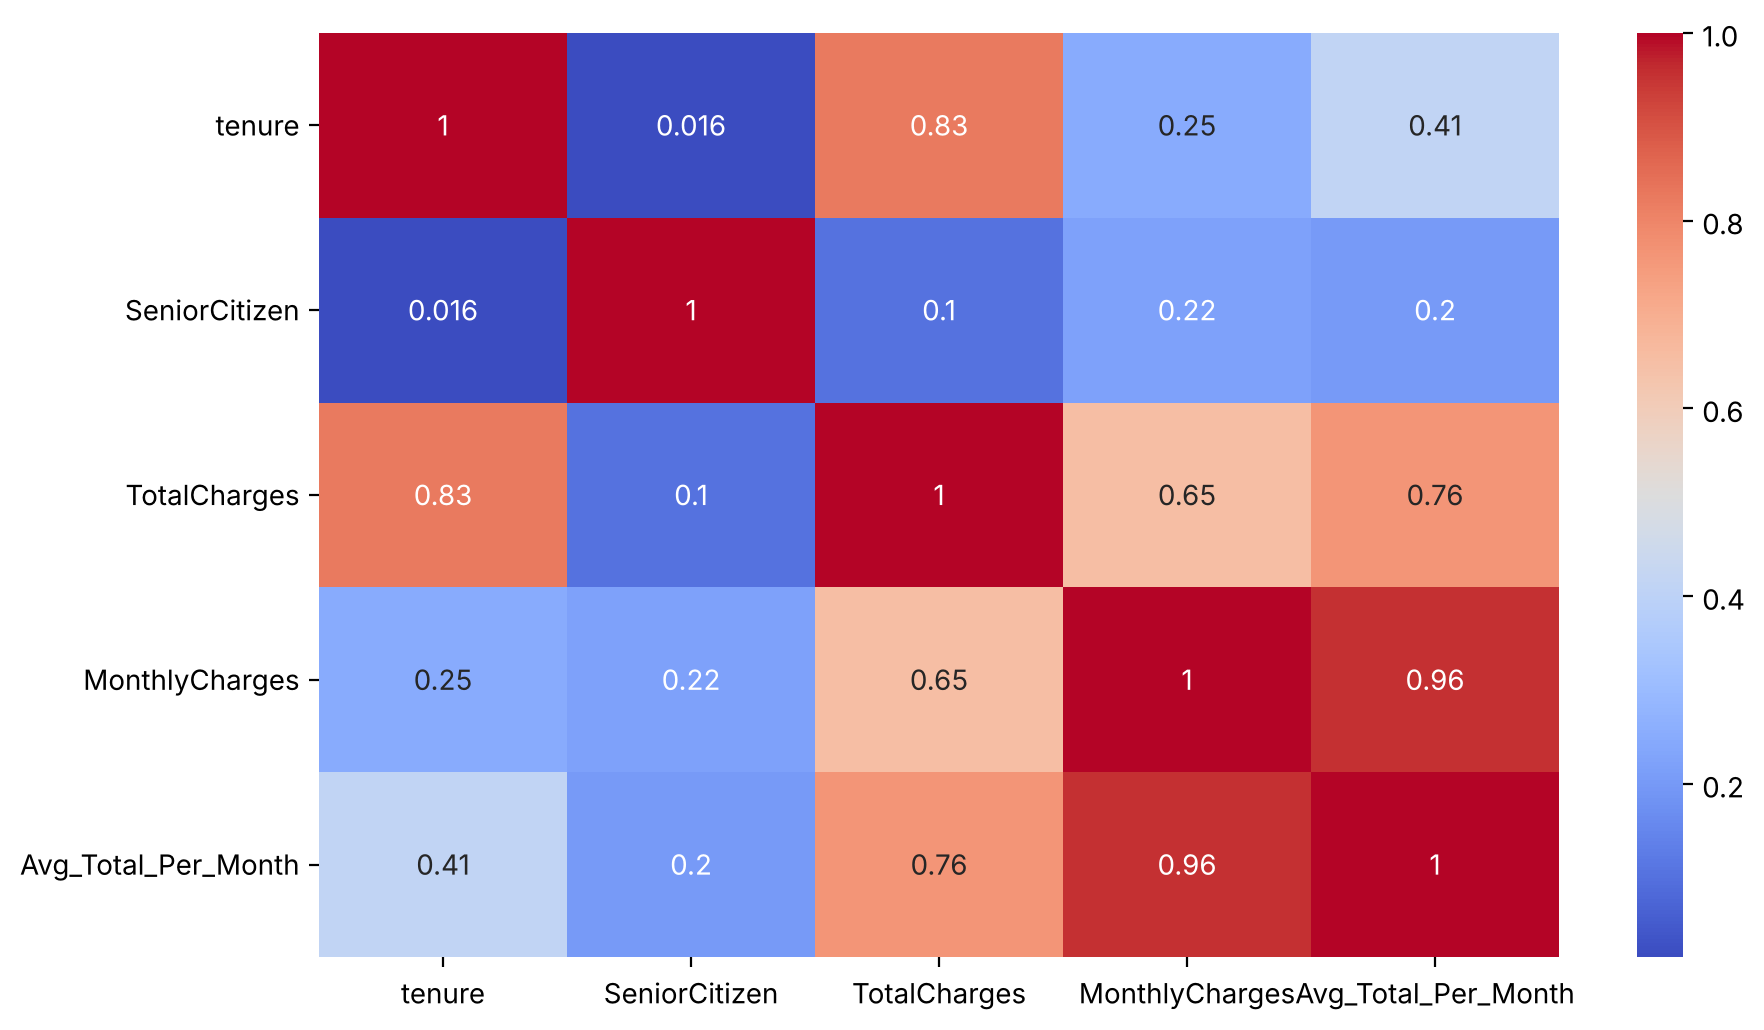

In [9]:
num_cols = ['tenure', 'SeniorCitizen', 'TotalCharges', 'MonthlyCharges', 'Avg_Total_Per_Month']
plt.figure(figsize=(10, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm')
plt.show()

In [10]:
X = df.drop(['Churn', 'customerID'], axis=1)
y = (df['Churn'] == 'Yes').astype(int)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
y_train.value_counts()

Churn
0    4130
1    1495
Name: count, dtype: int64

In [11]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
X_nums = X_train.select_dtypes(include=np.number).columns
X_cat = X_train.select_dtypes(exclude=np.number).columns
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('one-hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
transformer = ColumnTransformer([
    ('num', num_pipeline, X_nums),
    ('cat', cat_pipeline, X_cat)
])
full_pipeline = Pipeline([
    ('preprocessing', transformer),
    ('estimator', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

In [12]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(
    full_pipeline,
    {'estimator__C': [0.01, 0.1, 1, 10]},
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
grid.best_params_, grid.best_score_

({'estimator__C': 10}, np.float64(0.8490622494675554))

In [13]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
train_scores = cross_val_predict(best_model, X_train, y_train, cv=5, method='decision_function')
precisions, recalls, thresholds = precision_recall_curve(y_train, train_scores)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
threshold = thresholds[f1s.argmax()]
threshold

np.float64(-0.006953754092746511)

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
test_scores = best_model.decision_function(X_test)
y_pred = (test_scores > threshold).astype(int)
metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
    'roc_auc': roc_auc_score(y_test, test_scores)
}
metrics

{'accuracy': 0.7270788912579957,
 'precision': 0.49169435215946844,
 'recall': 0.7914438502673797,
 'f1': 0.6065573770491803,
 'roc_auc': 0.8371585279363879}

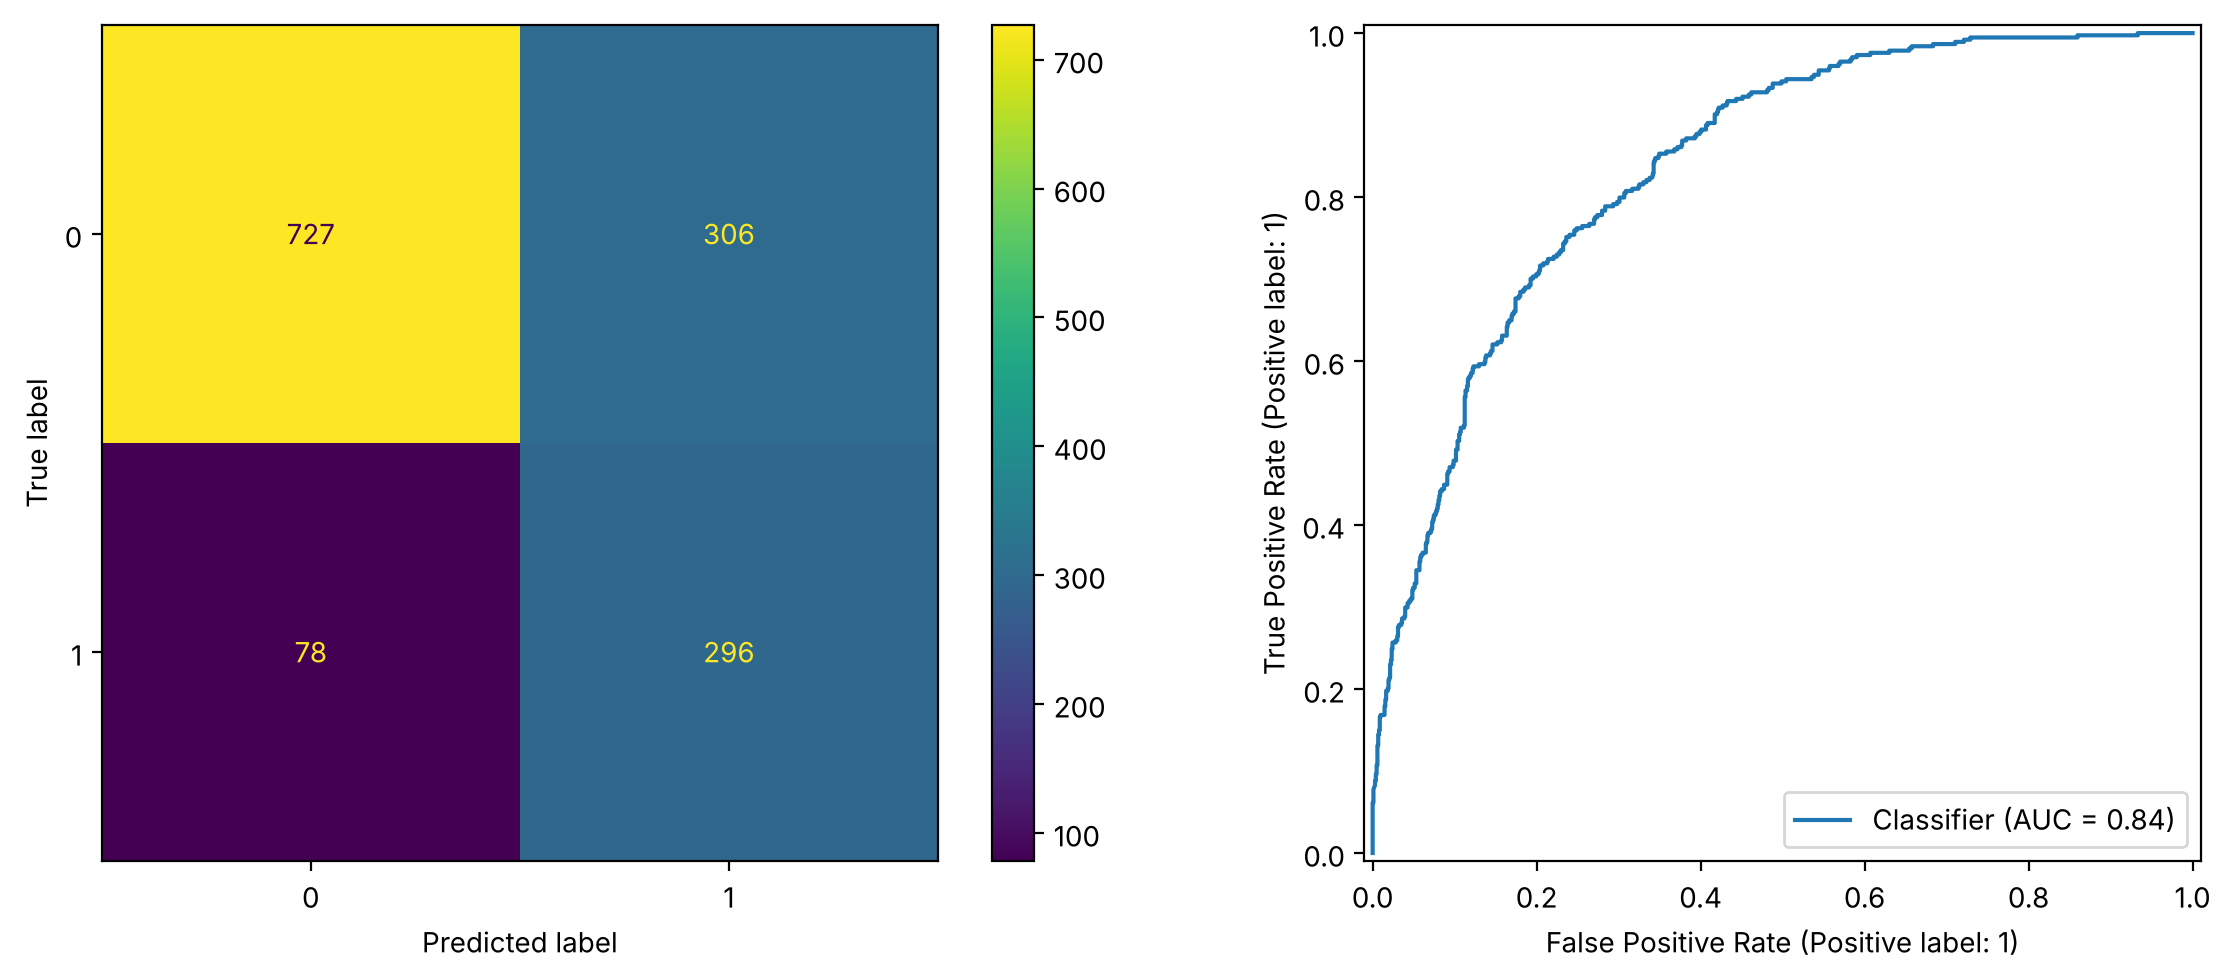

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=axes[0])
RocCurveDisplay.from_predictions(y_test, test_scores, ax=axes[1])
plt.tight_layout()
plt.show()

In [16]:
print(' | '.join(f'{k}: {v:.2f}' for k, v in metrics.items()))

accuracy: 0.73 | precision: 0.49 | recall: 0.79 | f1: 0.61 | roc_auc: 0.84
